# Data VZP: kdy žena přijde na mamograf po pozvánce (diskrétní model přežití)

Data hackathonu (`data_vzp/Rakhaton2026.csv.gz`, popis v `data_vzp/Rakathon_Datove_rozhrani.md`):
1 344 556 adresných pozvánek 2020–2024 pro 508 527 žen pojištěných u VZP nepřetržitě 2015–2025.

Místo tří samostatných modelů (účast do 3, 6 a 12 měsíců, viz `vzp_catboost_shap.ipynb`) jeden
CatBoost model **hazardu**: šance, že žena přijde v intervalu 0–3, 3–6 nebo 6–12 měsíců, pokud
nepřišla dřív. Pravděpodobnost účasti do konce intervalu k je 1 − ∏(1 − h_j), takže horizonty jsou
vždy konzistentní. **Pásma** (věk, délka registrace u praktika a gynekologa) jsou **pořadová čísla**,
ne kategorie; jedinou kategorií zůstává územní pracoviště VZP.

Notebook ukazuje jen agregáty, žádné řádky jednotlivých žen.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_hazard"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
HOR = ["3M", "6M", "12M"]
INT = ["0–3", "3–6", "6–12"]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS
BANDS = ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
REG = {"<2": 1, "2-5": 2, ">5": 3}  # chybějící = žádná registrace = 0
CAT = ["VZP_TERRITORIAL_AREA"]

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in AN:
    d[c] = (d[c] == "A").astype(int)
assert d.AGE_BAND.str.fullmatch(r"\d{2}-\d{2}").all()
d["AGE_BAND"] = d.AGE_BAND.str[:2].astype(int)  # dolní mez pásma: 40, 45, …, 70
for c in BANDS[1:]:
    assert (d[c].isna() | d[c].isin(REG)).all()
    d[c] = d[c].map(REG).fillna(0).astype(int)

# štítky jsou vnořené (3M ⊂ 6M ⊂ 12M); interval události: 1 = 0–3, 2 = 3–6, 3 = 6–12, 4 = do 12 měsíců nepřišla
assert ((d[LABELS[0]] <= d[LABELS[1]]) & (d[LABELS[1]] <= d[LABELS[2]])).all()
d["UDALOST"] = 4 - d[LABELS].sum(axis=1)
FEATURES = [c for c in d.columns if c not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE", "UDALOST"]]
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {d.INVITATION_DATE.min():%Y-%m} až {d.INVITATION_DATE.max():%Y-%m} · {len(FEATURES)} prediktorů")
print("prediktory:", ", ".join(FEATURES))

1,344,556 pozvánek · 508,527 žen · 2020-01 až 2024-12 · 19 prediktorů
prediktory: AGE_BAND, VZP_TERRITORIAL_AREA, PRIOR_INVITATION_COUNT, MONTHS_LAST_INVITATION, INVITATION_SEQUENCE, HEALTHCARE_CONTACT_12M_CNT, FIRST_INVITATION, INSURANCE_DURATION_YEARS, GP_REGISTERED, GP_REG_DURATION_BAND, GYN_REGISTERED_FLAG, GYN_REG_DURATION_BAND, PRIOR_SCREEN_COUNT_5Y, MONTHS_SINCE_LAST_SCREEN, NEVER_SCREENED_BEFORE_FLAG, GP_PREVENTION_24M_CNT, GYN_PREVENTION_24M_CNT, OTHER_SCREENING_36M_CNT, DENTAL_PREVENTION_24M_CNT


## 1 · Přehled: účast a hazard po letech (jen agregáty)

In [2]:
rok = d.INVITATION_DATE.dt.year
PREHLED = pd.DataFrame({"pozvánek": rok.value_counts().sort_index()})
for h, y in zip(HOR, LABELS):
    PREHLED[f"účast do {h}"] = d.groupby(rok)[y].mean()
for k, nm in zip((1, 2, 3), INT):
    r = d.UDALOST >= k
    PREHLED[f"hazard {nm}"] = (d.UDALOST[r] == k).groupby(rok[r]).mean()
PREHLED.to_csv(OUT / "prehled_po_letech.csv")
PREHLED.round(3)

,pozvánek,účast do 3M,účast do 6M,účast do 12M,hazard 0–3,hazard 3–6,hazard 6–12
INVITATION_DATE,,,,,,,
2020,266502,0.064,0.115,0.178,0.064,0.055,0.071
2021,279010,0.075,0.130,0.197,0.075,0.060,0.077
2022,275993,0.076,0.131,0.199,0.076,0.060,0.079
2023,266585,0.071,0.127,0.198,0.071,0.060,0.082
2024,256466,0.071,0.124,0.192,0.071,0.057,0.078


## 2 · Model hazardu

Časové rozdělení jako v `vzp_catboost_shap.ipynb`: učení na pozvánkách do června 2023, early stopping
(log-loss) na 2. pololetí 2023, test na roce 2024. Každá pozvánka má jeden řádek za interval, ve
kterém byla „v riziku“ (ještě nepřišla); číslo intervalu je prediktor, takže stromy dovolí, aby se
vliv sloupců v čase měnil.

In [3]:
train = d[d.INVITATION_DATE < "2023-07-01"]
valid = d[(d.INVITATION_DATE >= "2023-07-01") & (d.INVITATION_DATE < "2024-01-01")]
test = d[d.INVITATION_DATE >= "2024-01-01"]
FS = FEATURES + ["INTERVAL"]

def roztahni(df):
    """Jeden řádek za interval v riziku; y = 1 v intervalu, kdy žena přišla."""
    parts = []
    for k in (1, 2, 3):
        r = df.UDALOST >= k
        parts.append(df.loc[r, FEATURES].assign(INTERVAL=k, y=(df.UDALOST[r] == k).astype(int)))
    return pd.concat(parts)

def model_hazardu(tr, va, cat):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="Logloss",
                           od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
    m.fit(Pool(tr[FS], tr.y, cat_features=cat), eval_set=Pool(va[FS], va.y, cat_features=cat))
    return m

def predikce(m, df, cat):
    """Hazardy h_k a kumulativní pravděpodobnosti účasti do 3, 6 a 12 měsíců."""
    H = np.column_stack([m.predict_proba(Pool(df[FEATURES].assign(INTERVAL=k), cat_features=cat))[:, 1]
                         for k in (1, 2, 3)])
    return H, 1 - np.cumprod(1 - H, axis=1)

pp_tr, pp_va = roztahni(train), roztahni(valid)
print(f"pozvánek: učení {len(train):,} · ladění {len(valid):,} · test {len(test):,}")
print(f"řádků pozvánka-interval: učení {len(pp_tr):,} · ladění {len(pp_va):,}")
MH = model_hazardu(pp_tr, pp_va, CAT)
H, F = predikce(MH, test, CAT)
print(f"iterací: {MH.get_best_iteration()}")

pozvánek: učení 963,465 · ladění 124,625 · test 256,466
řádků pozvánka-interval: učení 2,700,854 · ladění 349,043


iterací: 750


## 3 · Výkon a kalibrace (test 2024)

,v riziku,pozorovaný hazard,predikovaný hazard
interval,,,
0–3,256466,0.071,0.068
3–6,238286,0.057,0.054
6–12,224629,0.078,0.075


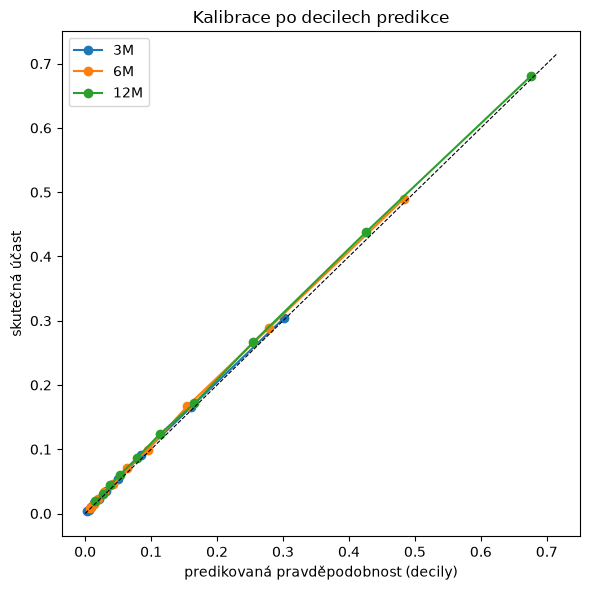

,účast,průměr predikce,AUROC,PR-AUC,log-loss
horizont,,,,,
3M,0.071,0.068,0.835,0.286,0.203
6M,0.124,0.119,0.836,0.431,0.287
12M,0.192,0.185,0.836,0.577,0.363


In [4]:
rows = []
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    yt = test[y].values
    rows.append({"horizont": h, "účast": yt.mean(), "průměr predikce": F[:, j].mean(),
                 "AUROC": roc_auc_score(yt, F[:, j]), "PR-AUC": average_precision_score(yt, F[:, j]),
                 "log-loss": log_loss(yt, F[:, j])})
VYKON = pd.DataFrame(rows).set_index("horizont")
VYKON.to_csv(OUT / "vykon.csv")

HZ = pd.DataFrame([{"interval": nm, "v riziku": int((test.UDALOST >= k).sum()),
                    "pozorovaný hazard": (test.UDALOST[test.UDALOST >= k] == k).mean(),
                    "predikovaný hazard": H[(test.UDALOST >= k).values, k - 1].mean()}
                   for k, nm in zip((1, 2, 3), INT)]).set_index("interval")
display(HZ.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    dec = pd.qcut(F[:, j], 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": F[:, j], "y": test[y].values}).groupby(dec).mean()
    ax.plot(g.p, g.y, "o-", label=h)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ax.set_xlabel("predikovaná pravděpodobnost (decily)"); ax.set_ylabel("skutečná účast")
ax.set_title("Kalibrace po decilech predikce"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "kalibrace.png", dpi=120); plt.show()
VYKON.round(3)

## 4 · Co model používá (SHAP po intervalech)

Přesný TreeSHAP na 20 000 testovacích pozvánkách; pro každý interval tytéž pozvánky s nastaveným
číslem intervalu. Hodnoty jsou v log-odds hazardu. Díky pořadovým pásmům lze vliv věku a délky
registrace číst jako křivku.

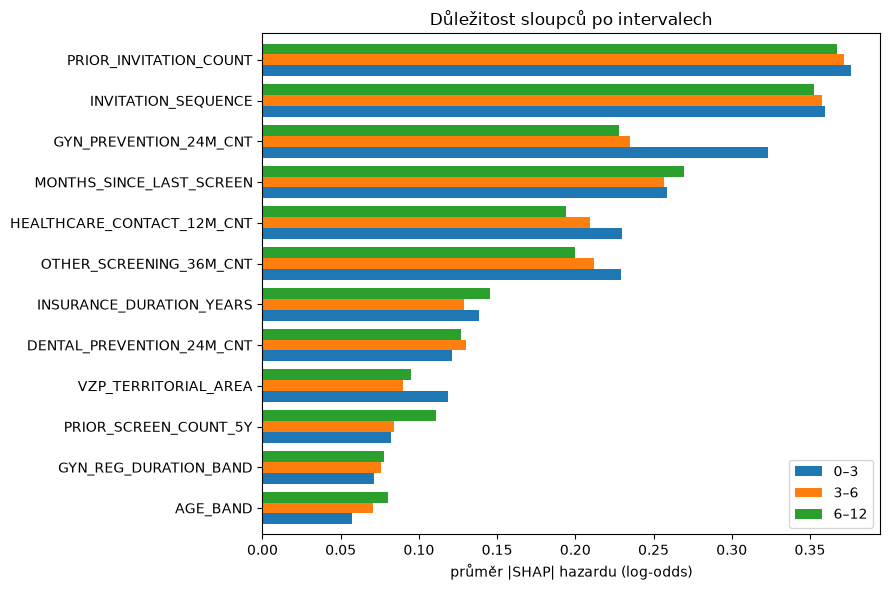

,0–3,3–6,6–12
PRIOR_INVITATION_COUNT,0.376,0.372,0.367
INVITATION_SEQUENCE,0.360,0.358,0.353
GYN_PREVENTION_24M_CNT,0.323,0.235,0.228
MONTHS_SINCE_LAST_SCREEN,0.259,0.257,0.269
HEALTHCARE_CONTACT_12M_CNT,0.230,0.209,0.194
OTHER_SCREENING_36M_CNT,0.229,0.212,0.200
INSURANCE_DURATION_YEARS,0.138,0.129,0.146
DENTAL_PREVENTION_24M_CNT,0.121,0.130,0.127
VZP_TERRITORIAL_AREA,0.118,0.090,0.095
PRIOR_SCREEN_COUNT_5Y,0.082,0.084,0.111


In [5]:
vz = test.sample(20_000, random_state=0)
SV, imp = {}, {}
for k, nm in zip((1, 2, 3), INT):
    sv = MH.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT), type="ShapValues")
    SV[nm] = sv[:, :len(FEATURES)]
    imp[nm] = np.abs(SV[nm]).mean(0)
IMP = pd.DataFrame(imp, index=FEATURES).sort_values("0–3", ascending=False)
IMP.round(3).to_csv(OUT / "shap_po_intervalech.csv")

fig, ax = plt.subplots(figsize=(9, 6))
IMP.iloc[:12][::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("průměr |SHAP| hazardu (log-odds)"); ax.set_title("Důležitost sloupců po intervalech")
plt.tight_layout(); plt.savefig(OUT / "shap_po_intervalech.png", dpi=120); plt.show()
IMP.round(3)

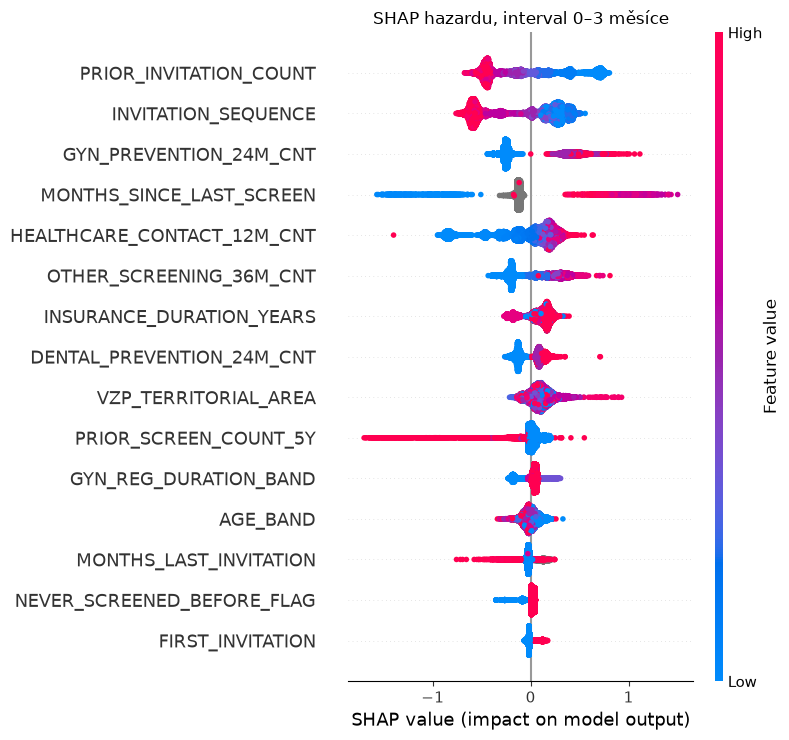

In [6]:
# beeswarm pro interval 0–3; územní pracoviště převedené na kód jen kvůli barvě
Xv = vz[FEATURES].assign(VZP_TERRITORIAL_AREA=vz.VZP_TERRITORIAL_AREA.astype("category").cat.codes)
shap.summary_plot(SV["0–3"], Xv, max_display=15, show=False)
plt.title("SHAP hazardu, interval 0–3 měsíce"); plt.tight_layout()
plt.savefig(OUT / "shap_beeswarm_0_3.png", dpi=120); plt.show()

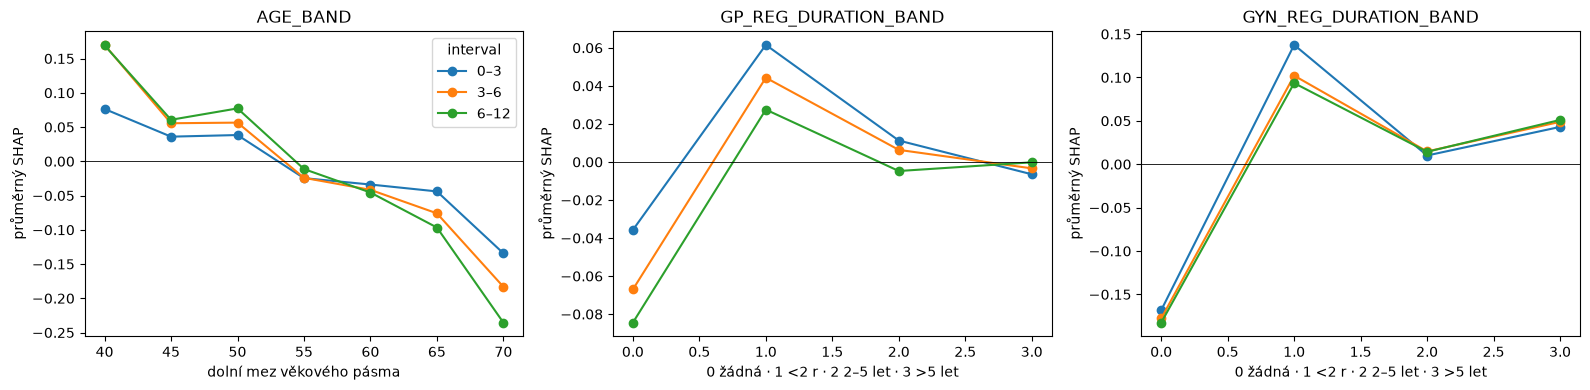

In [7]:
# průměrný SHAP podle hodnoty pásma a intervalu
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, BANDS):
    j = FEATURES.index(c)
    for nm in INT:
        pd.Series(SV[nm][:, j]).groupby(vz[c].values).mean().plot(ax=ax, marker="o", label=nm)
    ax.axhline(0, color="k", lw=0.6); ax.set_title(c); ax.set_ylabel("průměrný SHAP")
    ax.set_xlabel("dolní mez věkového pásma" if c == "AGE_BAND" else "0 žádná · 1 <2 r · 2 2–5 let · 3 >5 let")
axes[0].legend(title="interval")
plt.tight_layout(); plt.savefig(OUT / "shap_pasma.png", dpi=120); plt.show()

## 5 · Pásma jako pořadí vs. jako kategorie

Tentýž model hazardu, jen s pásmy jako kategoriemi (CatBoost je nahradí vyhlazenou účastí v pásmu
a pořadí nevyužije).

In [8]:
CAT_K = CAT + BANDS
MK = model_hazardu(pp_tr, pp_va, CAT_K)
HK, FK = predikce(MK, test, CAT_K)
rows = []
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    yt = test[y].values
    rows.append({"horizont": h, "AUROC pořadí": roc_auc_score(yt, F[:, j]), "AUROC kategorie": roc_auc_score(yt, FK[:, j]),
                 "PR-AUC pořadí": average_precision_score(yt, F[:, j]),
                 "PR-AUC kategorie": average_precision_score(yt, FK[:, j]),
                 "log-loss pořadí": log_loss(yt, F[:, j]), "log-loss kategorie": log_loss(yt, FK[:, j])})
SROV = pd.DataFrame(rows).set_index("horizont")
SROV.to_csv(OUT / "pasma_poradi_vs_kategorie.csv")
impk = {nm: np.abs(MK.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT_K),
                                             type="ShapValues")[:, :len(FEATURES)]).mean(0)
        for k, nm in zip((1, 2, 3), INT)}
IMPK = pd.DataFrame(impk, index=FEATURES)
print(f"iterací: pořadí {MH.get_best_iteration()}, kategorie {MK.get_best_iteration()}")
display(SROV.round(4))
pd.concat({"pořadí": IMP.loc[BANDS], "kategorie": IMPK.loc[BANDS]}, axis=1).round(3)

iterací: pořadí 750, kategorie 729


,AUROC pořadí,AUROC kategorie,PR-AUC pořadí,PR-AUC kategorie,log-loss pořadí,log-loss kategorie
horizont,,,,,,
3M,0.8350,0.8349,0.2859,0.2856,0.2027,0.2028
6M,0.8356,0.8356,0.4312,0.4312,0.2873,0.2873
12M,0.8362,0.8362,0.5769,0.5771,0.3630,0.3630


pořadí               kategorie              
                         0–3    3–6   6–12       0–3    3–6   6–12
AGE_BAND               0.058  0.070  0.080     0.061  0.069  0.072
GP_REG_DURATION_BAND   0.015  0.012  0.011     0.074  0.066  0.066
GYN_REG_DURATION_BAND  0.071  0.076  0.078     0.063  0.061  0.062

## 6 · Kde model funguje hůř: věková pásma a známé vs. nové ženy (test 2024)

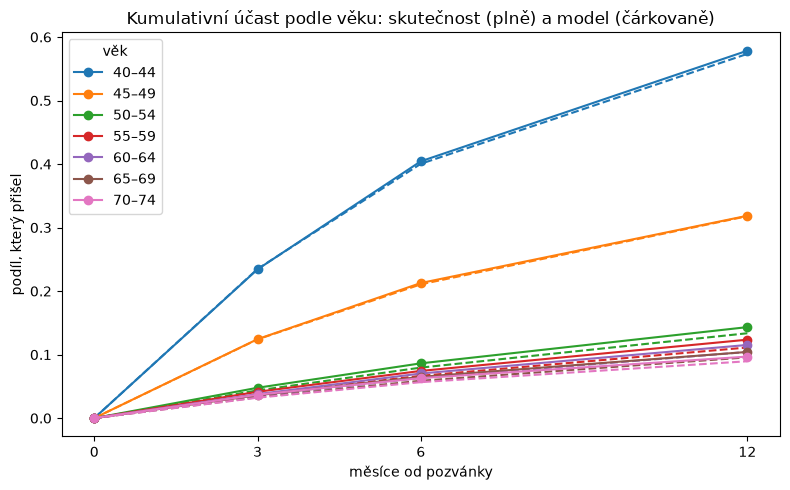

,pozvánek,účast 3M,predikce 3M,AUROC 3M,účast 6M,predikce 6M,AUROC 6M,účast 12M,predikce 12M,AUROC 12M
skupina,,,,,,,,,,
AGE_BAND = 40,9361,0.234,0.235,0.693,0.404,0.400,0.702,0.578,0.573,0.741
AGE_BAND = 45,71128,0.124,0.124,0.788,0.213,0.211,0.796,0.319,0.318,0.812
AGE_BAND = 50,42529,0.048,0.044,0.784,0.086,0.080,0.781,0.143,0.134,0.768
AGE_BAND = 55,40867,0.041,0.037,0.822,0.074,0.067,0.811,0.123,0.111,0.802
AGE_BAND = 60,40983,0.038,0.035,0.825,0.070,0.063,0.811,0.115,0.104,0.797
AGE_BAND = 65,44662,0.036,0.033,0.825,0.065,0.059,0.814,0.104,0.096,0.803
AGE_BAND = 70,6936,0.037,0.032,0.811,0.063,0.057,0.807,0.097,0.090,0.795
žena = nová,59153,0.182,0.182,0.735,0.312,0.305,0.744,0.455,0.447,0.774
žena = známá,197313,0.037,0.034,0.794,0.068,0.063,0.781,0.113,0.106,0.770


In [9]:
t = test.assign(**{f"p_{h}": F[:, j] for j, h in enumerate(HOR)})
t["žena"] = np.where(test.PERSON_ID.isin(set(train.PERSON_ID)), "známá", "nová")
rows = []
for col in ["AGE_BAND", "žena"]:
    for v, g in t.groupby(col):
        r = {"skupina": f"{col} = {v}", "pozvánek": len(g)}
        for h, y in zip(HOR, LABELS):
            r[f"účast {h}"] = g[y].mean()
            r[f"predikce {h}"] = g[f"p_{h}"].mean()
            r[f"AUROC {h}"] = roc_auc_score(g[y], g[f"p_{h}"])
        rows.append(r)
POD = pd.DataFrame(rows).set_index("skupina")
POD.to_csv(OUT / "podskupiny.csv")

# kumulativní účast: skutečnost (plně) vs. model (čárkovaně) podle věkového pásma
fig, ax = plt.subplots(figsize=(8, 5))
for i, (v, g) in enumerate(t.groupby("AGE_BAND")):
    c = f"C{i}"
    ax.plot([0, 3, 6, 12], [0, *g[LABELS].mean()], "-o", color=c, label=f"{v}–{v + 4}")
    ax.plot([0, 3, 6, 12], [0, *g[[f"p_{h}" for h in HOR]].mean()], "--", color=c)
ax.set_xticks([0, 3, 6, 12]); ax.set_xlabel("měsíce od pozvánky"); ax.set_ylabel("podíl, který přišel")
ax.set_title("Kumulativní účast podle věku: skutečnost (plně) a model (čárkovaně)"); ax.legend(title="věk")
plt.tight_layout(); plt.savefig(OUT / "kumulativni_ucast_vek.png", dpi=120); plt.show()
POD.round(3)

## Poznámky

* **Cílová proměnná není jen screening.** Kódy štítků (89178, 89223, 89225, 89314, 89510, 89814)
  zahrnují i doplňující snímky, ultrazvuk a biopsii.
* **Řádky jsou pozvánky, ne ženy** (až 5 na ženu). Vliv opakování rozebírá `vzp_catboost_shap.ipynb`,
  oddíl 5: AUROC uvnitř skupin známých a nových žen je nižší než celkové, interval přes převzorkování
  žen je úzký. U 12 měsíců může jedna mamografie započítat úspěch dvou pozvánek (asi 1,5 % kladných).
* **`VZP_TERRITORIAL_AREA` je územní pracoviště VZP, ne okres** (75 hodnot, velikosti neodpovídají
  okresům); okresní ukazatele na něj spolehlivě napojit nejde. Věk 75+ v datech není.
* **V datech nejsou nově pojištěné ženy** (jen nepřetržitě pojištěné 2015–2025), tedy ani
  příchozí z Ukrajiny po roce 2022.
* **SHAP popisuje model, ne příčiny.** O účinku intervencí rozhodne experiment (`docs/interventions.md`).